Chris McCarthy

DSC 640

Professor Schneider

Week 1 & 2 Assignment - Netflix Viewership

The angle I want to take for this assignment is pitching a potential movie to the board, but offering market research across both English and non-English audiences to gauge international interest and potential.

1. Initial imports and setup

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_DIR = Path("data")

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 6)

#these three films are in the top 10 for viewership popularity
#both non-English and English
#I'm using them as case studies for the purpose of the assignment

SELECTED = [
    "Leave the World Behind",
    "Society of the Snow",
    "Nowhere",
]

2. Loading and Previewing Datasets

In [3]:
global_df = pd.read_csv(DATA_DIR / "all-weeks-global-netflix(Top 10).csv")
countries_df = pd.read_csv(DATA_DIR / "all-weeks-countries-netflix(Top 10).csv")
popular_df = pd.read_csv(DATA_DIR / "most-popular-netflix(Top 10).csv")

global_df["week"] = pd.to_datetime(global_df["week"])
countries_df["week"] = pd.to_datetime(countries_df["week"])

for name, df in [
    ("Global", global_df),
    ("Countries", countries_df),
    ("Most Popular", popular_df),
]:
    print(f"\n{name}: {df.shape[0]:,} rows")
    display(df.head(3))

print(
    "Weekly global views begin:",
    global_df.loc[global_df["weekly_views"].notna(), "week"].min().date()
)
print("Last week in files:", global_df["week"].max().date())


Global: 5,840 rows


,week,category,weekly_rank,show_title,season_title,weekly_hours_viewed,runtime,weekly_views,cumulative_weeks_in_top_10,is_staggered_launch,episode_launch_details
0,2024-04-14,Films (English),1,What Jennifer Did,NaN,26100000,1.4500,18000000.0,1,False,NaN
1,2024-04-14,Films (English),2,Woody Woodpecker Goes to Camp,NaN,19600000,1.6667,11800000.0,1,False,NaN
2,2024-04-14,Films (English),3,Scoop,NaN,14600000,1.7167,8500000.0,2,False,NaN



Countries: 272,260 rows


,country_name,country_iso2,week,category,weekly_rank,show_title,season_title,cumulative_weeks_in_top_10
0,Argentina,AR,2024-04-14,Films,1,The Tearsmith,NaN,2
1,Argentina,AR,2024-04-14,Films,2,Stolen,NaN,1
2,Argentina,AR,2024-04-14,Films,3,"Love, Divided",NaN,1



Most Popular: 40 rows


,category,rank,show_title,season_title,hours_viewed_first_91_days,runtime,views_first_91_days
0,Films (English),1,Red Notice,NaN,454200000,1.9667,230900000
1,Films (English),2,Don't Look Up,NaN,408600000,2.3833,171400000
2,Films (English),3,The Adam Project,NaN,281000000,1.7833,157600000


Weekly global views begin: 2023-06-18
Last week in files: 2024-04-14


3. Preparing data for film

In [4]:
global_films = global_df[
    global_df["category"].str.startswith("Films")
].copy()

country_films = countries_df[
    countries_df["category"].eq("Films")
].copy()

popular_films = popular_df[
    popular_df["category"].str.startswith("Films")
].copy()

popular_films["language_group"] = (
    popular_films["category"]
    .str.replace("Films (", "", regex=False)
    .str.replace(")", "", regex=False)
)

selected_global = global_films[
    global_films["show_title"].isin(SELECTED)
].copy()

selected_countries = country_films[
    country_films["show_title"].isin(SELECTED)
].copy()

assert set(SELECTED).issubset(set(popular_films["show_title"]))
assert selected_global["weekly_views"].notna().all()

Visuals for Netflix Presentation to Board

1. First Visual - Total Views over First 91 Days Across 20 Films

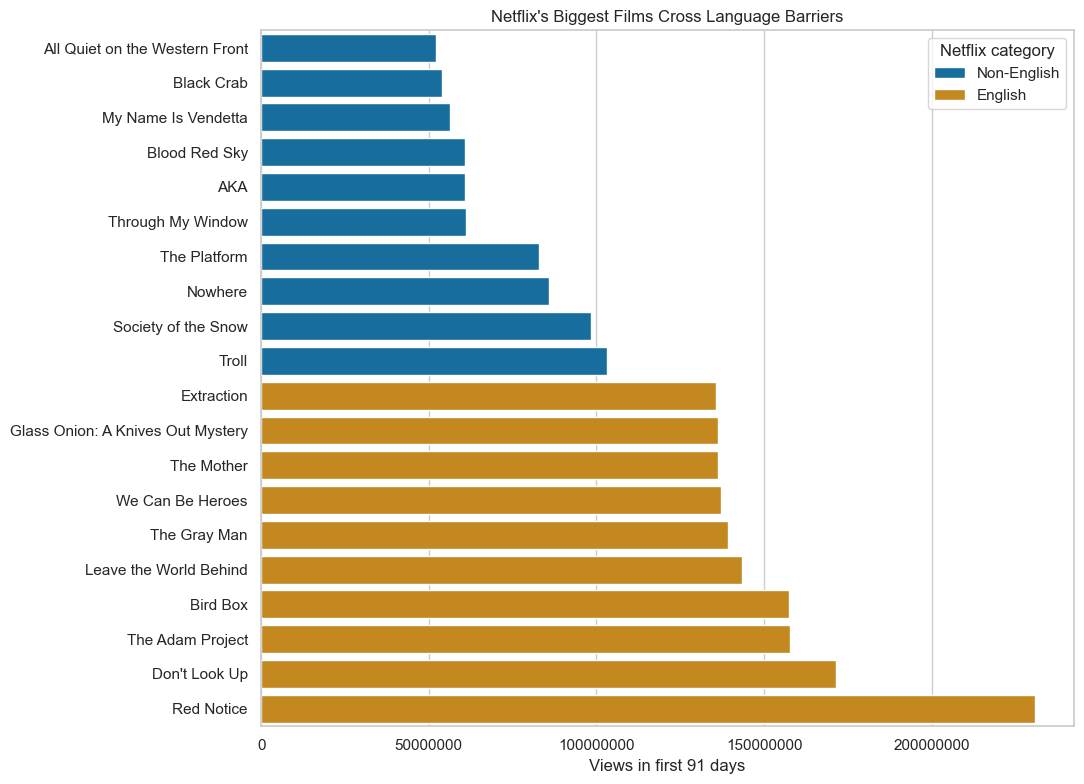

In [5]:
chart = popular_films.sort_values("views_first_91_days")

fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(
    data=chart,
    x="views_first_91_days",
    y="show_title",
    hue="language_group",
    dodge=False,
    ax=ax,
)

ax.set(
    title="Netflix's Biggest Films Cross Language Barriers",
    xlabel="Views in first 91 days",
    ylabel="",
)
ax.ticklabel_format(axis="x", style="plain")
ax.legend(title="Netflix category")
plt.tight_layout()
plt.show()

Netflix has a strong selection of films with meaningful viewing hours in the first 91 days. Importantly, both English and Non-English films show they can attract big audiences.

2. Second Visual - Weekly Viewing Non-English

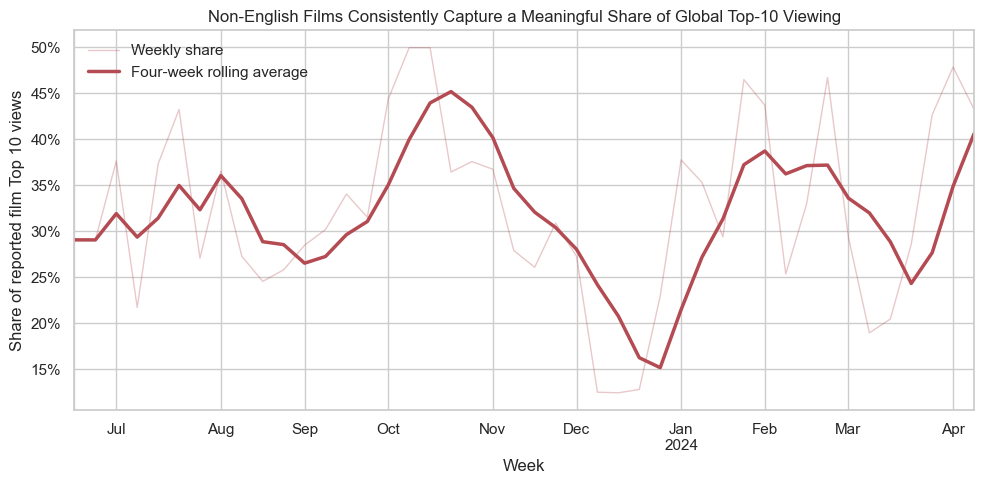

In [6]:
weekly = (
    global_films.dropna(subset=["weekly_views"])
    .groupby(["week", "category"], as_index=False)["weekly_views"]
    .sum()
)

weekly_wide = weekly.pivot(
    index="week",
    columns="category",
    values="weekly_views",
)

weekly_wide["non_english_share"] = (
    weekly_wide["Films (Non-English)"]
    / (
        weekly_wide["Films (English)"]
        + weekly_wide["Films (Non-English)"]
    )
)

share = weekly_wide["non_english_share"]
rolling_share = share.rolling(window=4, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))

share.plot(
    ax=ax,
    color="#b44b52",
    alpha=0.30,
    linewidth=1,
    label="Weekly share",
)

rolling_share.plot(
    ax=ax,
    color="#b44b52",
    linewidth=2.5,
    label="Four-week rolling average",
)

ax.set(
    title="Non-English Films Consistently Capture a Meaningful Share of Global Top-10 Viewing",
    xlabel="Week",
    ylabel="Share of reported film Top 10 views",
)

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0%}")
)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

This visual presents international / Non-English demand is a real market and not a one off trend or fad. While initially it may seem risky to tangle with potential language barriers, this graph shows that international audiences are an opportunity to be tapped into and make up a meaningful number of viewing hours in the top 10.

3. Visual Three - Popular Films Based on Country

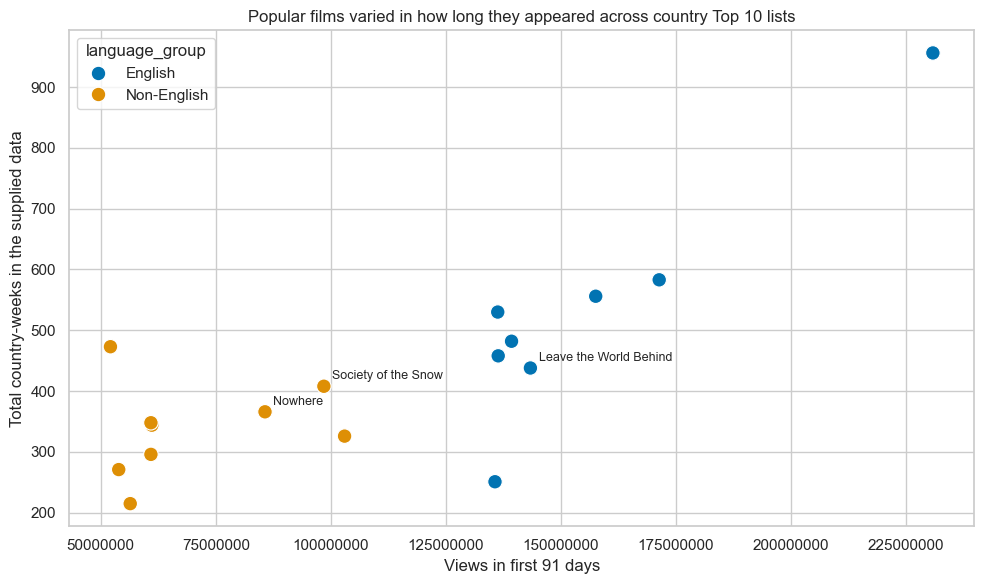

In [7]:
country_weeks = (
    country_films
    .groupby("show_title")
    .size()
    .rename("country_weeks")
    .reset_index()
)


observed_titles = set(global_films["show_title"])

presence_chart = (
    popular_films[
        popular_films["show_title"].isin(observed_titles)
    ]
    .merge(country_weeks, on="show_title", how="left")
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=presence_chart,
    x="views_first_91_days",
    y="country_weeks",
    hue="language_group",
    s=110,
    ax=ax,
)

for _, row in presence_chart[
    presence_chart["show_title"].isin(SELECTED)
].iterrows():
    ax.annotate(
        row["show_title"],
        (row["views_first_91_days"], row["country_weeks"]),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9,
    )

ax.set(
    title="Popular films varied in how long they appeared across country Top 10 lists",
    xlabel="Views in first 91 days",
    ylabel="Total country-weeks in the supplied data",
)
ax.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

This demonstrates the number of 'country-weeks' a film spent in the top 10 across the world. In other words, every week spent in any one countries' top 10 for views. So one week in two different countries would be two 'country-weeks.' The goal is to show the spread of views for these films in the top 10 along with the sheer magnitude regarding viewing hours. There's also some variance in global staying power when it comes to popularity.

4. Visual Four - Film's Overall Global Viewing Trajectory

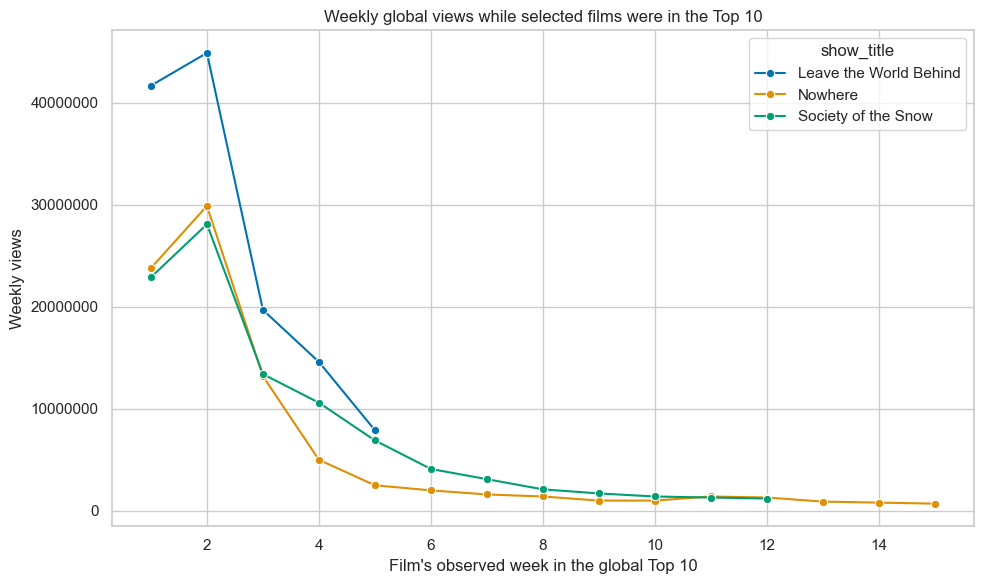

In [8]:
trajectory = selected_global.sort_values(
    ["show_title", "week"]
).copy()

trajectory["top_10_week"] = (
    trajectory.groupby("show_title").cumcount() + 1
)

fig, ax = plt.subplots()
sns.lineplot(
    data=trajectory,
    x="top_10_week",
    y="weekly_views",
    hue="show_title",
    marker="o",
    ax=ax,
)

ax.set(
    title="Weekly global views while selected films were in the Top 10",
    xlabel="Film's observed week in the global Top 10",
    ylabel="Weekly views",
)
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

Successful films generate most of their viewing early in their Top-10 run. Viewing is heavily front-loaded so launch window matters enormously here. Attention falls off quickly after the initial surge in interest so for a film to have a successful release, the initial viewing window needs to be maximized.

5. Visual Five - Film Longevity Across Countries

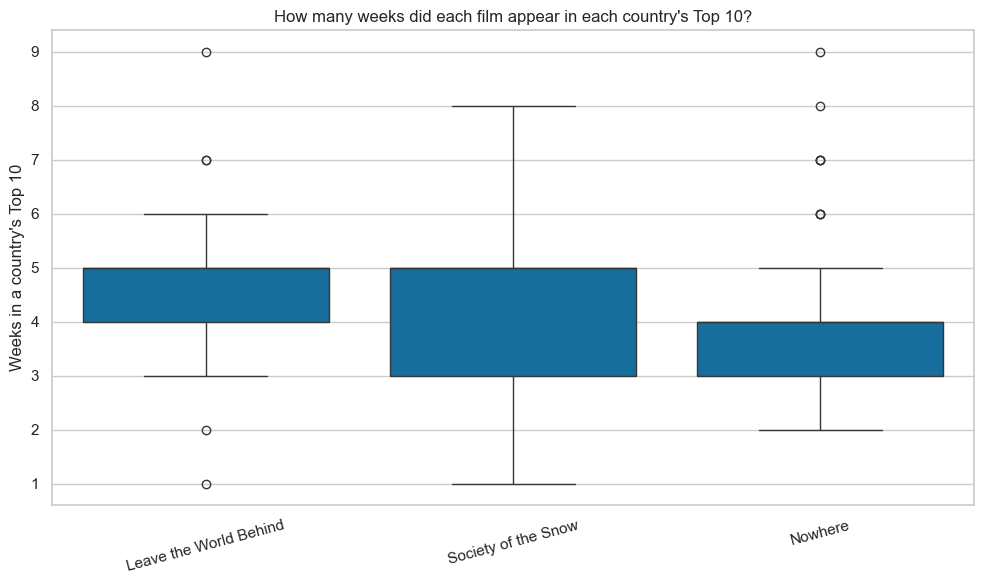

In [9]:
country_duration = (
    selected_countries
    .groupby(["show_title", "country_name"])
    .agg(weeks_in_top_10=("week", "nunique"))
    .reset_index()
)

fig, ax = plt.subplots()
sns.boxplot(
    data=country_duration,
    x="show_title",
    y="weeks_in_top_10",
    order=SELECTED,
    ax=ax,
)

ax.set(
    title="How many weeks did each film appear in each country's Top 10?",
    xlabel="",
    ylabel="Weeks in a country's Top 10",
)
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

The boxplot helps visualize how long each respective film stayed in the top 10 in different countries. On average, the median for all 3 films was approximately 4-5 weeks, with some highs of 8-9 weeks in certain countries. This is useful information because we can see the potential viewing timeline for films of this caliber. We can also see how films definitely benefit from their target markets, having longer runtimes in certain places.

6. Visual Six - Countries Films were most Popular

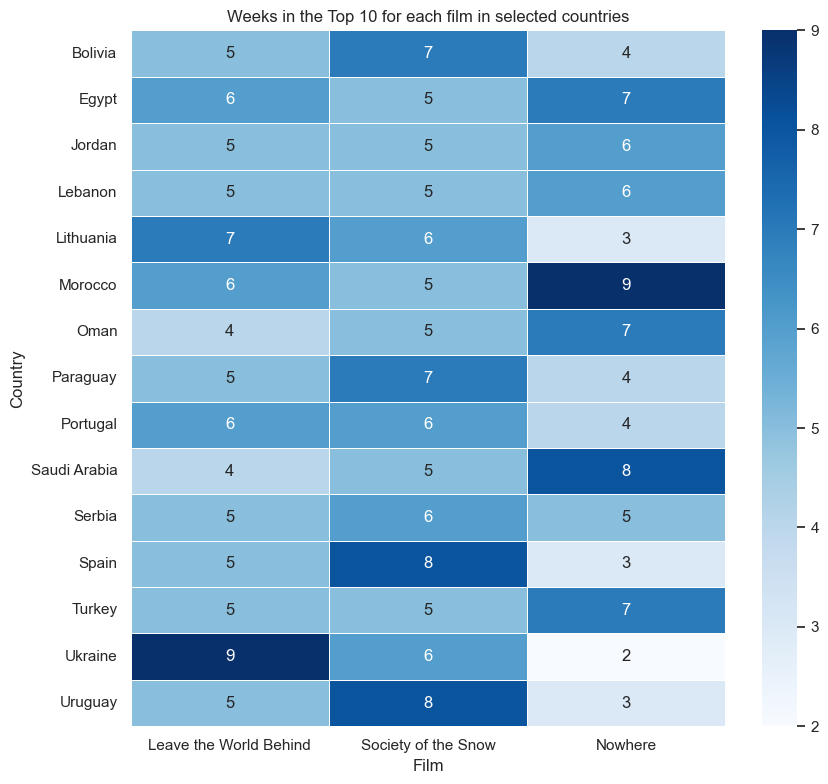

In [10]:
top_countries = (
    selected_countries
    .groupby("country_name")
    .size()
    .nlargest(15)
    .index
)

weeks_by_country = (
    selected_countries[
        selected_countries["country_name"].isin(top_countries)
    ]
    .groupby(["country_name", "show_title"])["week"]
    .nunique()
    .unstack()
    .reindex(columns=SELECTED)
)

fig, ax = plt.subplots(figsize=(9, 8))

sns.heatmap(
    weeks_by_country,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.5,
    ax=ax,
)

ax.set(
    title="Weeks in the Top 10 for each film in selected countries",
    xlabel="Film",
    ylabel="Country",
)

plt.tight_layout()
plt.show()

This heatmap helps convey how long each film was in the top 10 across these different countries. The darker the color, the higher the number of weeks spent in the top 10. Building on the previous visual, this one continues to show the variability between countries when it comes to viewership.

PRESENTATION / PITCH

Based on the research and visuals, I want to pitch that international audiences represent a fantastic opportunity. Non-English films have shown great viewership and staying power regarding weeks spent in top 10s across different countries. This means popularity and interest is sustainable in markets beyond domestic.

Also important to note is striking while it's hot. Audiences lose interest pretty rapidly after a movie's peak into the top 10, so it'll be prudent for us to capitalize on this window when marketing our movie. The general idea here is to find markets where audiences have shown a history of sustained interest in films, and to tap into those markets while also broadening our reach.

The final pitch is as follows: let's move forward with funding for development of film that incorporates both domestic and international audiences. To field test this, we'll rely on information similar to what I've provided here in my six visuals so we can build out a foundation of market knowledge. Once fully confident, we'll pull the trigger on target countries and how to conceptualize a film that meets the demands and interests of those audiences.

Audience: Netflix board

Purpose: to secure funding for an international film project

Medium: visual presentation and commentary

Design Choices: simple color contrast and clear visuals for maximum clarity and understanding


Ethical Considerations:

The data is from credible sources which gives confidence. However, the data does not provide information on unsuccessful films, so there's some selection bias there. The data also doesn't specifically capture sentiment and viewer scores of the films, although sustained time in the top 10 does imply a good reception. Finally, language may be unrelated to a film's success and instead, it just has to do with domestic vs international markets in addition to variability based on country.